# MEDE · CP3 · Relatii si protocol experimental
**Student:** Simon Alessia 
**Unitate de analiza:** Localitatea / UAT (UAT × An) · Judetul Prahova

**Intrebarea de explorare:** Care localitati cresc teritorial (ca suprafata construita) fara sa inregistreze o crestere a populatiei?

**Sursa datelor:** Eurostat (populatie, 2010–2025, pas 5 ani) + GHSL (suprafata construita, km²).
**Format:** UAT × An — 104 UAT-uri, 4 momente de timp (2010, 2015, 2020, 2025).

### Ce fac in acest notebook pentru CP3:
1. **Harta relatiilor** dintre cele doua surse, ca sa vad daca aduc informatii complementare.
2. **Protocolul experimental** pentru metodele de reducere a dimensionalitatii (split 80/20 pe UAT-uri, testare cu 10 seed-uri).
3. **Evaluarea metodelor:** Compar PCA (ca baseline liniar) cu t-SNE si un Autoencoder (neliniare), pe ambele spatii de trasaturi (niveluri vs. dinamica).
4. **Stabilitatea:** verific rezultatele pe seed-uri diferite si pe subperioade (2010–2020 vs. 2015–2025).


In [1]:
# Import bibliotecile necesare pentru analiza si vizualizare
import os, re, unicodedata, warnings, itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist

# Import modulele din scikit-learn pentru machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.cross_decomposition import CCA
from sklearn.feature_selection import mutual_info_regression

# Setari pentru un aspect curat al graficelor
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

# --- Configuratia protocolului experimental ---
SEEDS     = list(range(10))   # Voi rula pe 10 seed-uri pentru a testa stabilitatea
K_DIM     = 2                 # Reducem la 2 dimensiuni pentru a putea interpreta vizual
KNN       = 5                 # Folosesc 5 vecini pentru metrica Trustworthiness
TEST_SIZE = 0.20              # Oprim 20% din UAT-uri strict pentru testare (evitam leakage)
METHODS   = ['PCA', 't-SNE', 'Autoencoder'] # Metodele alese pentru comparatie

# Cream folderele pentru salvarea rezultatelor
print('Configurare protocol finalizata.')

Configurare protocol finalizata.


## 1. Incarcarea si alinierea datelor
Refac alinierea de la CP2: unesc datele din Eurostat si GHSL folosind o cheie normalizata (numele UAT-ului fara diacritice sau prefixe).

In [2]:
EUROSTAT = 'Eurostat_Prahova_2010_2025.csv'
GHSL = 'GHSL_Prahova_2010_2025_CP2.csv'

# Citirea datelor (compatibil cu Colab sau local)
if os.path.exists(EUROSTAT):                      # CSV-urile in acelasi folder cu notebook-ul
    p_e, p_g = EUROSTAT, GHSL
elif os.path.exists(os.path.join('data', EUROSTAT)):
    p_e, p_g = os.path.join('data', EUROSTAT), os.path.join('data', GHSL)
else:
    # Daca rulam pe Colab si nu exista folderul data, cerem incarcarea
    from google.colab import files
    print('Va rugam sa incarcati cele doua fisiere CSV:')
    up = files.upload()
    p_e = next(f for f in up if 'eurostat' in f.lower())
    p_g = next(f for f in up if 'ghsl' in f.lower())

eu, gh = pd.read_csv(p_e), pd.read_csv(p_g)

# Functie pentru curatarea numelor de localitati
def normalize_name(s):
    s = unicodedata.normalize('NFKD', str(s).lower().strip()).encode('ascii', 'ignore').decode('ascii')
    s = re.sub(r'^(municipiul|orasul|oras|comuna)\s+', '', s)
    return re.sub(r'[^a-z0-9]', '', s)

eu['key'] = eu['UAT_Name'].map(normalize_name)
gh['key'] = gh['name'].map(normalize_name)

# Transformam datele GHSL in format tabelar lat (wide)
gw = gh.pivot_table(index='key', columns='An', values='Built_km2', aggfunc='mean')
gw.columns = [f'Built_{c}' for c in gw.columns]
df = eu.merge(gw.reset_index(), on='key', how='inner').reset_index(drop=True)

print('UAT-uri aliniate cu succes:', len(df))

# --- Feature Engineering ---
# Pentru a raspunde la intrebare, calculez si dinamica (ratele logaritmice de crestere)
YEARS = [2010, 2015, 2020, 2025]
INTV  = list(zip(YEARS[:-1], YEARS[1:]))

for a, b in INTV:
    df[f'dPop_{a}_{b}']   = np.log(df[f'Pop_{b}'] / df[f'Pop_{a}'])
    df[f'dBuilt_{a}_{b}'] = np.log(df[f'Built_{b}'] / df[f'Built_{a}'])

# Dinamica pe intreaga perioada si indicele GAP (diferenta dintre ritmul de construire si cel de populare)
df['dPop_tot']   = np.log(df['Pop_2025'] / df['Pop_2010'])
df['dBuilt_tot'] = np.log(df['Built_2025'] / df['Built_2010'])
df['gap']        = df['dBuilt_tot'] - df['dPop_tot'] 

# Definesc clar cele doua spatii de trasaturi analizate
SPACES = {
    'Niveluri': {'Pop': [f'Pop_{y}' for y in YEARS], 'Built': [f'Built_{y}' for y in YEARS]},
    'Dinamica': {'Pop': [f'dPop_{a}_{b}' for a, b in INTV], 'Built': [f'dBuilt_{a}_{b}' for a, b in INTV]},
}
for sp in SPACES: 
    SPACES[sp]['Pop+Built'] = SPACES[sp]['Pop'] + SPACES[sp]['Built']

def view_cols(space, view, window=None):
    if view == 'Pop+Built':
        return view_cols(space, 'Pop', window) + view_cols(space, 'Built', window)
    c = SPACES[space][view]
    return c if window is None else (c[:-1] if window == 'P1' else c[1:])

# Analizez putin fenomenul pe care il caut:
pop_scade = df.Pop_2025 < df.Pop_2010
built_creste = df.Built_2025 > df.Built_2010
pop_scade_built_creste = pop_scade & built_creste

print(f"\nLocalitati unde populatia scade SI construitul creste (2010→2025): {pop_scade_built_creste.sum()} din {len(df)}")
print("Observatie: Pentru ca aproape toate cresc in construit, ma voi folosi de indicele continuu 'gap' pentru vizualizare.")

# Verificare: trebuie sa am exact 104 UAT-uri unice
assert len(df) == 104 and df['key'].is_unique, 'alinierea nu a dat 104 UAT-uri unice'
print('Verificare OK: 104 UAT-uri unice.')

UAT-uri aliniate cu succes: 104

Localitati unde populatia scade SI construitul creste (2010→2025): 96 din 104
Observatie: Pentru ca aproape toate cresc in construit, ma voi folosi de indicele continuu 'gap' pentru vizualizare.
Verificare OK: 104 UAT-uri unice.


## 1b. De ce lucrez in doua spatii: niveluri si dinamica
La CP2 am lucrat pe **niveluri** (Pop_t si Built_t, 8 trasaturi). PCA a aratat ca PC1 (≈95%) reflecta in principal *marimea* UAT-ului (Ploiesti domina). E un rezultat util ca referinta, dar intrebarea mea e despre **crestere**, nu despre marime. De aceea la CP3 compar metodele in ambele spatii:
- **Niveluri**: continuitate cu CP2 (matricea X neschimbata);
- **Dinamica**: log-rate de crestere pe intervale de 5 ani, unde marimea UAT-ului dispare si ramane ritmul de schimbare.

Intrebarea ramane aceeasi; schimb doar reprezentarea in care o citesc.

## 2. Harta Relatiilor
Vreau sa vad daca sursele mele (Populatie vs Construit) se suprapun ca informatie sau aduc date noi. 
Voi folosi corelatia Spearman, informatia mutuala si o analiza a corelatiei canonice (CCA) cu test de permutare pentru validare.

In [3]:
# 1. Corelatia Spearman pe niveluri
lev_cols = SPACES['Niveluri']['Pop+Built']
R_lev = df[lev_cols].corr(method='spearman')

# 2. Corelatia cu lag pe spatiul dinamic (evidentiaza intarzieri intre fenomene)
dP = SPACES['Dinamica']['Pop']
dB = SPACES['Dinamica']['Built']
lag_corr = pd.DataFrame(
    [[stats.spearmanr(df[p], df[b])[0] for b in dB] for p in dP],
    index=[f'ΔPop {a}–{b}' for a, b in INTV], 
    columns=[f'ΔBuilt {a}–{b}' for a, b in INTV]
)

# 3. Informatia Mutuala
def calc_mutual_info(A, B, seed=0):
    return np.array([mutual_info_regression(A, B[:, j], n_neighbors=5, random_state=seed) for j in range(B.shape[1])]).T

MI_dyn = pd.DataFrame(
    calc_mutual_info(StandardScaler().fit_transform(df[dP]), StandardScaler().fit_transform(df[dB])),
    index=lag_corr.index, columns=lag_corr.columns
)

# 4. Canonical Correlation Analysis (CCA) cu test de permutare (ca sa vedem daca e semnificativ statistic)
def canon_corr(A, B):
    A = A - A.mean(0)
    B = B - B.mean(0)
    Qa, _ = np.linalg.qr(A)
    Qb, _ = np.linalg.qr(B)
    return np.linalg.svd(Qa.T @ Qb, compute_uv=False)

rng = np.random.default_rng(0)
cca_rows = []

for sp in SPACES:
    A = StandardScaler().fit_transform(df[SPACES[sp]['Pop']])
    B = StandardScaler().fit_transform(df[SPACES[sp]['Built']])
    
    r = canon_corr(A, B)
    # Permutam B de 500 de ori pentru a construi distributia nula
    null_dist = np.array([canon_corr(A, B[rng.permutation(len(B))])[0] for _ in range(500)])
    
    # Validam si pe un split de test pentru a asigura robustetea
    cv = []
    for s in SEEDS:
        tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
        sa = StandardScaler().fit(df.iloc[tr][SPACES[sp]['Pop']])
        sb = StandardScaler().fit(df.iloc[tr][SPACES[sp]['Built']])
        m = CCA(n_components=1, scale=False, max_iter=2000).fit(
            sa.transform(df.iloc[tr][SPACES[sp]['Pop']]), 
            sb.transform(df.iloc[tr][SPACES[sp]['Built']])
        )
        u, v = m.transform(sa.transform(df.iloc[te][SPACES[sp]['Pop']]), sb.transform(df.iloc[te][SPACES[sp]['Built']]))
        cv.append(np.corrcoef(u[:, 0], v[:, 0])[0, 1])
        
    cca_rows.append(dict(
        spatiu=sp, 
        r1=r[0], 
        null95=np.percentile(null_dist, 95), 
        p_perm=(1 + (null_dist >= r[0]).sum()) / 501,
        r1_test_medie=np.mean(cv)
    ))

cca_tab = pd.DataFrame(cca_rows).set_index('spatiu')

# 5. Graf kNN de similaritate (cat de mult coincid vecinii din Pop cu cei din Built)
def get_knn(Z, k=KNN):
    return NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]

def calc_jaccard(A, B):
    return np.mean([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(A, B)])

knn_rows = []
for sp in SPACES:
    Gp = get_knn(StandardScaler().fit_transform(df[SPACES[sp]['Pop']]))
    Gb = get_knn(StandardScaler().fit_transform(df[SPACES[sp]['Built']]))
    knn_rows.append(dict(spatiu=sp, jaccard_Pop_vs_Built=calc_jaccard(Gp, Gb)))

knn_tab = pd.DataFrame(knn_rows).set_index('spatiu')

print('Corelatia canonica (CCA) si valoarea p (test de permutare):')
display(cca_tab.round(3))
print(f"Concluzie: pe dinamica (cresteri) relatia e mai slaba (r1={cca_tab.loc['Dinamica','r1']:.2f}) fata de niveluri (r1={cca_tab.loc['Niveluri','r1']:.2f}), deci sursele nu sunt complet redundante cand analizam ritmul de dezvoltare.")

Corelatia canonica (CCA) si valoarea p (test de permutare):


,r1,null95,p_perm,r1_test_medie
spatiu,,,,
Niveluri,0.986,0.549,0.002,0.883
Dinamica,0.661,0.373,0.002,0.611


Concluzie: pe dinamica (cresteri) relatia e mai slaba (r1=0.66) fata de niveluri (r1=0.99), deci sursele nu sunt complet redundante cand analizam ritmul de dezvoltare.


In [4]:
# Completez harta relatiilor: nivelul aleator pentru Jaccard, afisare si salvare
pop_down_built_up = pop_scade_built_creste
rng2 = np.random.default_rng(0)
for sp in SPACES:
    Gp = get_knn(StandardScaler().fit_transform(df[SPACES[sp]['Pop']]))
    knn_tab.loc[sp, 'jaccard_aleator'] = np.mean([
        calc_jaccard(Gp, np.array([rng2.choice(np.delete(np.arange(len(df)), i), KNN, replace=False) for i in range(len(df))]))
        for _ in range(50)])

print('Corelatia cu lag (Spearman, dinamica):'); display(lag_corr.round(3))
print('Informatia mutuala (dinamica):');        display(MI_dyn.round(3))
print('Acordul vecinilor kNN Pop vs. Built (Jaccard) fata de nivelul aleator:'); display(knn_tab.round(3))


Corelatia cu lag (Spearman, dinamica):


,ΔBuilt 2010–2015,ΔBuilt 2015–2020,ΔBuilt 2020–2025
ΔPop 2010–2015,0.497,0.475,0.475
ΔPop 2015–2020,0.299,0.293,0.434
ΔPop 2020–2025,0.589,0.487,0.511


Informatia mutuala (dinamica):


,ΔBuilt 2010–2015,ΔBuilt 2015–2020,ΔBuilt 2020–2025
ΔPop 2010–2015,0.192,0.159,0.116
ΔPop 2015–2020,0.125,0.098,0.117
ΔPop 2020–2025,0.168,0.095,0.145


Acordul vecinilor kNN Pop vs. Built (Jaccard) fata de nivelul aleator:


,jaccard_Pop_vs_Built,jaccard_aleator
spatiu,,
Niveluri,0.114,0.027
Dinamica,0.046,0.028


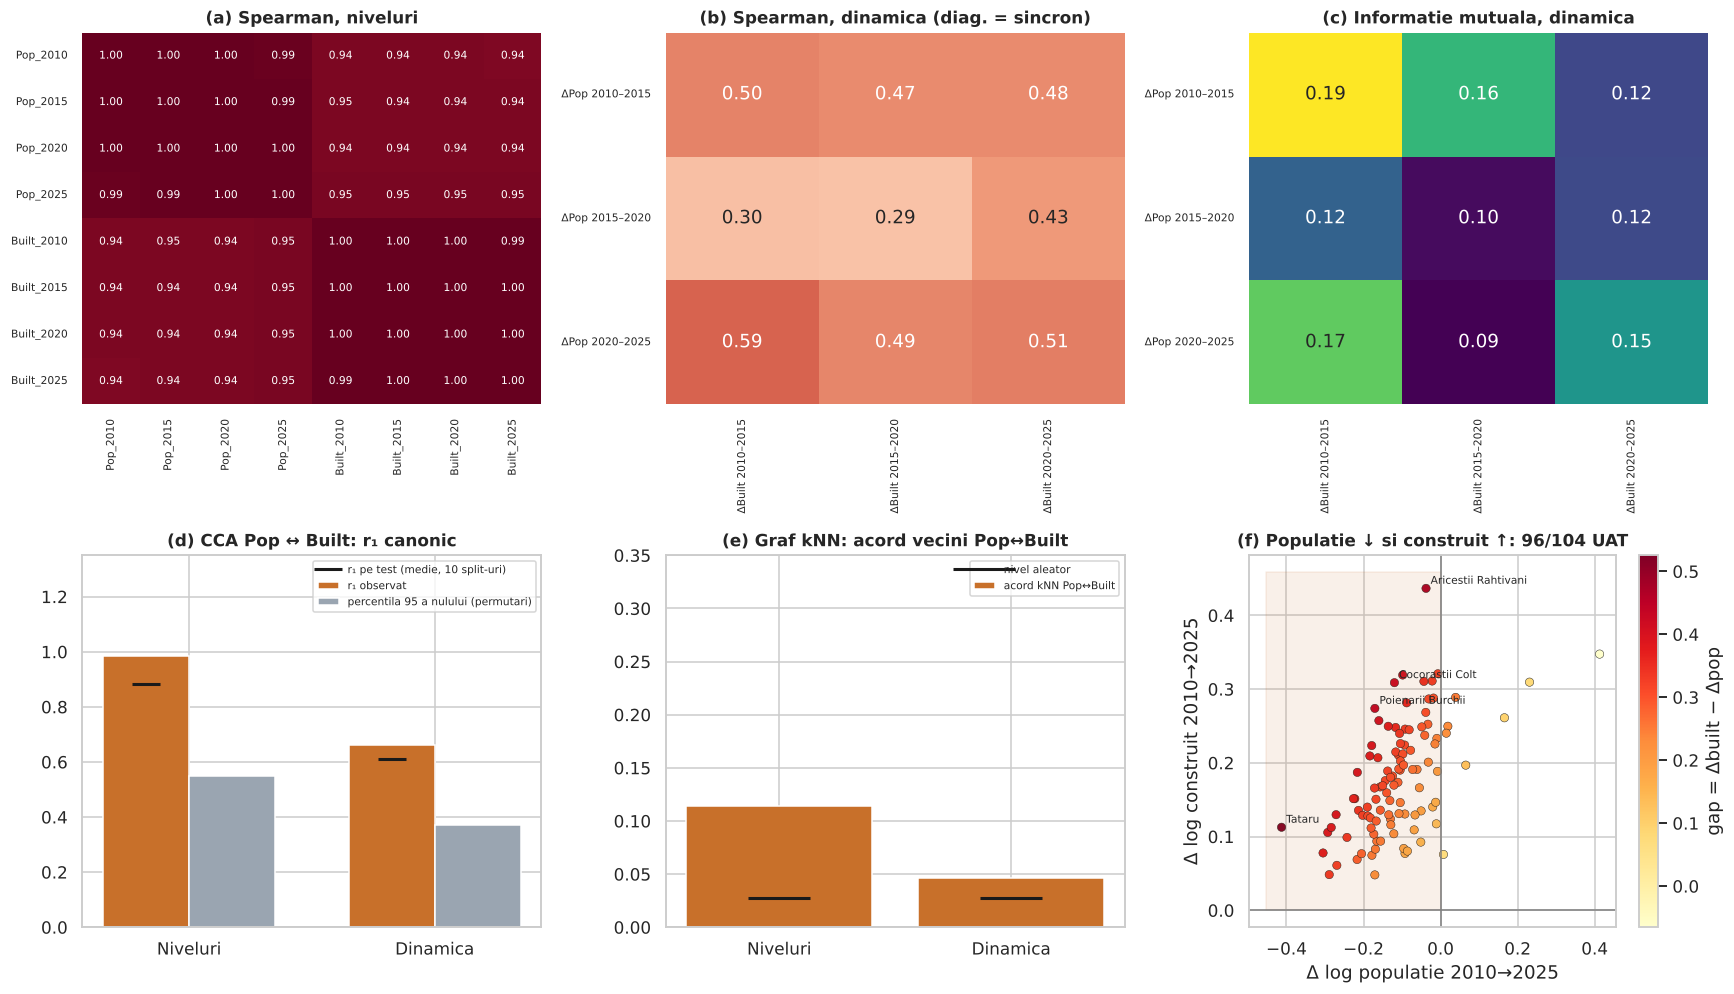

In [5]:
# ---- Figura "Harta relatiilor" ----
fig, ax = plt.subplots(2, 3, figsize=(16, 9.2))
sns.heatmap(R_lev, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0, 0], cbar=False, annot_kws={"size": 7})
ax[0, 0].set_title("(a) Spearman, niveluri", fontsize=11)
sns.heatmap(lag_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0, 1], cbar=False)
ax[0, 1].set_title("(b) Spearman, dinamica (diag. = sincron)", fontsize=11)
sns.heatmap(MI_dyn, annot=True, fmt=".2f", cmap="viridis", ax=ax[0, 2], cbar=False)
ax[0, 2].set_title("(c) Informatie mutuala, dinamica", fontsize=11)
for a in ax[0, :]: a.tick_params(axis="both", labelsize=7)

x = np.arange(len(cca_tab)); w = 0.35
ax[1, 0].bar(x - w/2, cca_tab.r1, w, label="r₁ observat", color="#C8702A")
ax[1, 0].bar(x + w/2, cca_tab.null95, w, label="percentila 95 a nulului (permutari)", color="#9AA5B1")
ax[1, 0].plot(x - w/2, cca_tab.r1_test_medie, "k_", ms=18, mew=2, label="r₁ pe test (medie, 10 split-uri)")
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(cca_tab.index); ax[1, 0].set_ylim(0, 1.05)
ax[1, 0].set_title("(d) CCA Pop ↔ Built: r₁ canonic", fontsize=11); ax[1, 0].set_ylim(0, 1.35); ax[1, 0].legend(fontsize=7, loc="upper right", ncol=1)

ax[1, 1].bar(knn_tab.index, knn_tab.jaccard_Pop_vs_Built, color="#C8702A", label="acord kNN Pop↔Built")
ax[1, 1].plot(knn_tab.index, knn_tab.jaccard_aleator, "k_", ms=40, mew=2, label="nivel aleator")
ax[1, 1].set_title("(e) Graf kNN: acord vecini Pop↔Built", fontsize=11); ax[1, 1].set_ylim(0, 0.35); ax[1, 1].legend(fontsize=7, loc="upper right")

sc = ax[1, 2].scatter(df.dPop_tot, df.dBuilt_tot, c=df.gap, cmap="YlOrRd", s=30, edgecolor="k", lw=0.3)
ax[1, 2].axvline(0, color="grey", lw=1); ax[1, 2].axhline(0, color="grey", lw=1)
ax[1, 2].fill_betweenx([0, ax[1, 2].get_ylim()[1]], ax[1, 2].get_xlim()[0], 0, color="#C8702A", alpha=0.10)
ax[1, 2].set_xlabel("Δ log populatie 2010→2025"); ax[1, 2].set_ylabel("Δ log construit 2010→2025")
ax[1, 2].set_title(f"(f) Populatie ↓ si construit ↑: {pop_down_built_up.sum()}/104 UAT", fontsize=11)
for i in df.nlargest(4, "gap").index:
    ax[1, 2].annotate(df.UAT_Name[i].replace("Oras ", "").replace("Municipiul ", ""), (df.dPop_tot[i], df.dBuilt_tot[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, ax=ax[1, 2], label="gap = Δbuilt − Δpop")
plt.tight_layout(); plt.show()

**Cum se citeste.** In *niveluri*, Pop si Built sunt aproape redundante (ambele masoara marimea UAT; panoul a, d, e). In *dinamica* legatura dintre surse este mult mai slaba (panourile b, c, d), deci Built aduce informatie **noua** fata de populatie exact pe intrebarea noastra (panoul f).

## 3. Protocolul experimental (identic pentru toate metodele)

| Element | Alegere |
|---|---|
| **Unitate / X** | 104 UAT × trasaturi. *Niveluri*: Pop_t, Built_t (t=2010…2025) → 4 + 4 = 8 trasaturi (matricea X din CP2). *Dinamica*: log-rate pe 3 intervale de 5 ani → 3 + 3 = 6 trasaturi |
| **Vederi** | **Pop** (doar Eurostat), **Built** (doar GHSL), **Pop+Built** (concatenare = date combinate) |
| **Metode** | **PCA** (baseline liniar), **t-SNE** (neliniar, local), **Autoencoder** (invatat; MLP d–8–k–8–d, tanh). Pentru relatia dintre surse (multi-view): **CCA** (sectiunea 2) |
| **Dimensiune** | k = 2 pentru toate metodele (comparabil si vizualizabil); k se rafineaza prin ablatie la CP4 |
| **Split** | Aleator 80/20 pe UAT-uri, repetat cu 10 seed-uri. *Scaler-ul si reducerea se potrivesc (fit) doar pe train* si se aplica pe test (fara leakage). Spatial nu e posibil: nu avem coordonate/vecinatati in tabele |
| **t-SNE out-of-sample** | t-SNE nu are `transform`; UAT-urile de test sunt plasate prin interpolare kNN (k=5, pondere 1/distanta) fata de UAT-urile de train in spatiul de intrare. Se raporteaza ca atare |
| **Metrici** | *Locala*: trustworthiness (k=5) si continuity (k=5) pe test. *Globala*: corelatia Spearman dintre distantele din X si din Z. *Reconstructie*: R² de reconstructie pe test (PCA = varianta explicata pe test, Autoencoder; n/a pentru t-SNE). *Varianta explicata* PCA pe train |
| **Stabilitate – seed-uri** | 10 seed-uri (split + initializare t-SNE/AE). Raportam media si intervalul de incredere 95% (t-Student). In plus: acordul kNN (Jaccard) intre embeddingurile din seed-uri diferite |
| **Stabilitate – subperioade** | Aceleasi metode pe fereastra **P1** (2010–2020) si **P2** (2015–2025): diferenta de trustworthiness (P2−P1) si acordul kNN intre cele doua embeddinguri |
| **Baseline** | PCA pe acelasi split, acelasi k, aceleasi metrici. Daca alternativa nu bate PCA, acesta este rezultatul |

## 3. Functiile pentru protocolul experimental
Definesc modul in care se aplica scalarea si metodele pe seturile de antrenament si test, pentru a calcula corect metrica de baza (Trustworthiness) si R-patrat (pentru Autoencoder).

In [6]:
# Calculez metrica de baza pentru reprezentare: Trustworthiness (si Continuity)
def get_trust_cont(Xs, Z, k=KNN):
    k = int(min(k, max(1, len(Xs) // 2 - 1)))
    return trustworthiness(Xs, Z, n_neighbors=k), trustworthiness(Z, Xs, n_neighbors=k)

# Functie care antreneaza metoda aleasa DOAR pe datele de train
def fit_reducer(method, Xtr, k, seed):
    if method == 'PCA':
        m = PCA(n_components=k, random_state=seed).fit(Xtr)
        return m.transform, m.inverse_transform, m.transform(Xtr)
        
    if method == 't-SNE':
        # t-SNE nu are o functie de transform pentru date noi. Il invat pe train, 
        # si folosesc un KNN ca sa asez datele de test in acelasi spatiu.
        emb = TSNE(n_components=k, perplexity=10, init='random', learning_rate='auto', max_iter=750, random_state=seed).fit_transform(Xtr)
        ext = KNeighborsRegressor(n_neighbors=5, weights='distance').fit(Xtr, emb)
        return ext.predict, None, emb
        
    if method == 'Autoencoder':
        # Folosesc un Multi-Layer Perceptron care primeste X si trebuie sa prezica tot X, trecand printr-un strat ascuns de k dimensiuni
        ae = MLPRegressor(hidden_layer_sizes=(8, k, 8), activation='tanh', solver='lbfgs', alpha=1e-3, max_iter=3000, random_state=seed).fit(Xtr, Xtr)
        
        # Extrag matematic coeficientii ca sa separ reteaua in encoder si decoder
        enc = lambda Z: np.tanh(np.tanh(Z @ ae.coefs_[0] + ae.intercepts_[0]) @ ae.coefs_[1] + ae.intercepts_[1])
        dec = lambda C: np.tanh(C @ ae.coefs_[2] + ae.intercepts_[2]) @ ae.coefs_[3] + ae.intercepts_[3]
        return enc, dec, enc(Xtr)
        
    raise ValueError('Metoda necunoscuta!')

# Evaluez tot pipeline-ul pe un split train/test
def eval_split(Xraw_tr, Xraw_te, method, k, seed):
    sc = StandardScaler().fit(Xraw_tr) # Scaler fit DOAR pe train pentru a evita data leakage
    Xtr = sc.transform(Xraw_tr)
    Xte = sc.transform(Xraw_te)
    
    enc, dec, _ = fit_reducer(method, Xtr, k, seed)
    Zte = enc(Xte) # Reprezentarea redusa aplicata pe test
    
    t, c = get_trust_cont(Xte, Zte)
    out = dict(trust=t, cont=c, dist_rho=stats.spearmanr(pdist(Xte), pdist(Zte))[0], recon_r2=np.nan)
    
    # Calculam R^2 pentru reconstructie (daca metoda permite)
    if dec is not None:
        out['recon_r2'] = 1 - np.sum((Xte - dec(Zte)) ** 2) / np.sum(Xte ** 2)
        
    if method == 'PCA':
        out['var_expl_train'] = PCA(n_components=k).fit(Xtr).explained_variance_ratio_.sum()
        out['var_expl_k1'] = PCA(n_components=1).fit(Xtr).explained_variance_ratio_.sum()
    return out

# Functie pentru calculul Intervalului de Incredere 95%
def calc_ci95(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) > 1:
        return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return np.nan

# Functie pentru sumarizarea rezultatelor
def summarize_results(df, group_cols, metrics):
    g = df.groupby(group_cols)[metrics]
    return g.mean().join(g.agg(calc_ci95), rsuffix='_ci95')

print('Functiile de protocol sunt gata!')

Functiile de protocol sunt gata!


## 4. Evaluarea metodelor pe 10 seed-uri
Aici rulez protocolul pe toate combinatiile posibile (Spatiu × Sursa de date × Metoda), generand tabelul de dovezi pentru checkpoint.

In [7]:
print('Rulez modelele pe cele 10 seed-uri... Va rugam asteptati.')
t0 = time.time()
rezultate_brute = []

for sp in SPACES:
    for view in ['Pop', 'Built', 'Pop+Built']:
        X_all = df[view_cols(sp, view)].values
        for s in SEEDS:
            # Impart datele folosind seed-ul curent
            tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
            
            for m in METHODS:
                eval_metrics = eval_split(X_all[tr], X_all[te], m, K_DIM, s)
                rezultate_brute.append(dict(
                    spatiu=sp, vedere=view, metoda=m, seed=s, **eval_metrics
                ))

res_df = pd.DataFrame(rezultate_brute)
print(f'S-au efectuat {len(res_df)} rulari in {time.time()-t0:.1f} secunde.')

# Sumarizam rezultatele calculand mediile si intervalele de incredere (IC95)
main_summary = summarize_results(res_df, ['spatiu', 'vedere', 'metoda'], ['trust', 'recon_r2']).reset_index()

# Formatez tabelul ca sa arate profesionist, exact ca in prezentarea PowerPoint
def format_trust(row):
    return f"{row['trust']:.3f} ± {row['trust_ci95']:.3f}"

tabel_final = main_summary.assign(Trust_Formatat=main_summary.apply(format_trust, axis=1))
tabel_pivot = tabel_final.pivot(index='metoda', columns=['spatiu', 'vedere'], values='Trust_Formatat').reindex(METHODS)

print('\nTABELUL PRINCIPAL: Trustworthiness pe setul de Test (k=5, Medie ± IC95)')
display(tabel_pivot)

Rulez modelele pe cele 10 seed-uri... Va rugam asteptati.
S-au efectuat 180 rulari in 17.4 secunde.

TABELUL PRINCIPAL: Trustworthiness pe setul de Test (k=5, Medie ± IC95)


spatiu            Dinamica                                     Niveluri                              
vedere               Built            Pop      Pop+Built          Built            Pop      Pop+Built
metoda                                                                                               
PCA          0.981 ± 0.011  0.955 ± 0.011  0.947 ± 0.019  1.000 ± 0.000  1.000 ± 0.000  0.999 ± 0.001
t-SNE        0.938 ± 0.017  0.893 ± 0.023  0.872 ± 0.014  0.965 ± 0.019  0.958 ± 0.018  0.956 ± 0.018
Autoencoder  0.939 ± 0.029  0.925 ± 0.019  0.856 ± 0.037  0.993 ± 0.007  0.998 ± 0.001  0.968 ± 0.020

In [8]:
# Redenumiri ca sa pot refolosi functiile de protocol in analizele de mai jos, si salvez tabelul principal
trust_cont, knn_idx, jaccard, ci95, summarize = get_trust_cont, get_knn, calc_jaccard, calc_ci95, summarize_results
res = res_df
main = summarize(res, ['spatiu', 'vedere', 'metoda'], ['trust', 'cont', 'dist_rho', 'recon_r2']).reset_index()
main = main.rename(columns=lambda c: c.replace('_ci95', '_ci'))

### Cine bate PCA-ul? 
Compar fiecare metoda cu PCA pe aceleasi split-uri (diferenta pereche pe seed, cu IC95). Ma uit si la reconstructie (R²) si la varianta explicata de PCA.

In [9]:
# Cine bate baseline-ul PCA? Diferenta pereche pe seed (aceleasi split-uri), IC95 al diferentei
piv = res.pivot_table(index=["spatiu", "vedere", "seed"], columns="metoda", values="trust")
cmp_rows = []
for (sp, v), g in piv.groupby(level=[0, 1]):
    for m in METHODS[1:]:
        d = (g[m] - g["PCA"]).values
        cmp_rows.append(dict(spatiu=sp, vedere=v, metoda=m, delta_trust_vs_PCA=d.mean(), ci95=ci95(d),
                             semnificativ="DA" if abs(d.mean()) > ci95(d) else "nu", castiga=("metoda" if d.mean() > 0 else "PCA") if abs(d.mean()) > ci95(d) else "egal"))
cmp_tab = pd.DataFrame(cmp_rows)
display(cmp_tab.round(4))

# Reconstructie + varianta explicata (doar metodele cu decoder)
rec = summarize(res[res.metoda.isin(["PCA", "Autoencoder"])], ["spatiu", "vedere", "metoda"], ["recon_r2"]).reset_index()
ve  = summarize(res[res.metoda == "PCA"], ["spatiu", "vedere"], ["var_expl_k1", "var_expl_train"]).reset_index()
print("R² de reconstructie pe test (k=2):"); display(rec.round(3))
print("Varianta explicata PCA pe train (k=1 si k=2):"); display(ve.round(3))

,spatiu,vedere,metoda,delta_trust_vs_PCA,ci95,semnificativ,castiga
0,Dinamica,Built,t-SNE,-0.0436,0.0118,DA,PCA
1,Dinamica,Built,Autoencoder,-0.0423,0.0324,DA,PCA
2,Dinamica,Pop,t-SNE,-0.0621,0.0295,DA,PCA
3,Dinamica,Pop,Autoencoder,-0.03,0.0161,DA,PCA
4,Dinamica,Pop+Built,t-SNE,-0.0755,0.0271,DA,PCA
5,Dinamica,Pop+Built,Autoencoder,-0.0918,0.0311,DA,PCA
6,Niveluri,Built,t-SNE,-0.0352,0.0186,DA,PCA
7,Niveluri,Built,Autoencoder,-0.007,0.0066,DA,PCA
8,Niveluri,Pop,t-SNE,-0.042,0.018,DA,PCA
9,Niveluri,Pop,Autoencoder,-0.0023,0.0014,DA,PCA


R² de reconstructie pe test (k=2):


,spatiu,vedere,metoda,recon_r2,recon_r2_ci95
0,Dinamica,Built,Autoencoder,0.821,0.096
1,Dinamica,Built,PCA,0.933,0.024
2,Dinamica,Pop,Autoencoder,0.818,0.09
3,Dinamica,Pop,PCA,0.856,0.043
4,Dinamica,Pop+Built,Autoencoder,0.47,0.141
5,Dinamica,Pop+Built,PCA,0.759,0.057
6,Niveluri,Built,Autoencoder,0.903,0.142
7,Niveluri,Built,PCA,1,0
8,Niveluri,Pop,Autoencoder,-1.546,5.415
9,Niveluri,Pop,PCA,1,0


Varianta explicata PCA pe train (k=1 si k=2):


,spatiu,vedere,var_expl_k1,var_expl_train,var_expl_k1_ci95,var_expl_train_ci95
0,Dinamica,Built,0.777,0.935,0.011,0.006
1,Dinamica,Pop,0.777,0.902,0.02,0.01
2,Dinamica,Pop+Built,0.611,0.784,0.019,0.014
3,Niveluri,Built,0.998,1,0.001,0
4,Niveluri,Pop,0.999,1,0.001,0
5,Niveluri,Pop+Built,0.973,0.999,0.011,0.001


## 5. Stabilitate: seed-uri si subperioade
- **Seed-uri**: acordul kNN (Jaccard) intre embeddingurile obtinute cu seed-uri diferite pe aceleasi UAT-uri (PCA este determinista ⇒ 1).
- **Subperioade**: aceleasi metode pe fereastra P1 (2010–2020) vs. P2 (2015–2025). Raportam (i) diferenta de trustworthiness pe test P2−P1 si (ii) acordul kNN intre embeddingurile P1 si P2 (cu seed-uri diferite), comparat cu „plafonul" din spatiul de intrare.

In [10]:
t0 = time.time()
def embed_all(cols, method, seed):
    # embedding transductiv, nesupervizat, al tuturor UAT-urilor (pentru acorduri intre rulari si pentru figura)
    Xs = StandardScaler().fit_transform(df[cols].values)
    return fit_reducer(method, Xs, K_DIM, seed)[2], Xs

stab_seed, stab_win, win_tr, emb_cache = [], [], [], {}
for sp in SPACES:
    for view in ["Pop", "Built", "Pop+Built"]:
        cols = view_cols(sp, view)
        for m in METHODS:
            E = []
            for s in SEEDS:
                Z, Xs = embed_all(cols, m, s); E.append(knn_idx(Z)); emb_cache[(sp, view, m, s)] = Z
            pairs = [jaccard(E[i], E[j]) for i, j in itertools.combinations(range(len(E)), 2)]
            stab_seed.append(dict(spatiu=sp, vedere=view, metoda=m, jaccard_seed_medie=np.mean(pairs), jaccard_seed_min=np.min(pairs)))
            # subperioade
            tw = {}
            for w in ["P1", "P2"]:
                cw = view_cols(sp, view, w); Xw = df[cw].values
                tw[w] = []
                for s in SEEDS:
                    tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
                    tw[w].append(eval_split(Xw[tr], Xw[te], m, K_DIM, s)["trust"])
            d = np.array(tw["P2"]) - np.array(tw["P1"])
            J = []
            for s in SEEDS:
                Z1, X1 = embed_all(view_cols(sp, view, "P1"), m, s); Z2, X2 = embed_all(view_cols(sp, view, "P2"), m, s + 1000)
                J.append(jaccard(knn_idx(Z1), knn_idx(Z2)))
            ceil = jaccard(knn_idx(X1), knn_idx(X2))
            degen = len(view_cols(sp, view, "P1")) <= K_DIM      # d <= k: PCA e fara pierderi (trust=1 prin constructie) ⇒ comparatie neinformativa
            nan = np.nan
            stab_win.append(dict(spatiu=sp, vedere=view, metoda=m, d_trasaturi_fereastra=len(view_cols(sp, view, "P1")), degenerat=degen,
                                 trust_P1=nan if degen else np.mean(tw["P1"]), trust_P2=nan if degen else np.mean(tw["P2"]),
                                 delta_P2_P1=nan if degen else d.mean(), delta_ci95=nan if degen else ci95(d),
                                 jaccard_P1_P2=np.mean(J), jaccard_P1_P2_ci95=ci95(J), plafon_input=ceil))
stab_seed, stab_win = pd.DataFrame(stab_seed), pd.DataFrame(stab_win)
print(f"stabilitate calculata in {time.time()-t0:.0f}s")
print("Acord kNN intre seed-uri (Jaccard; 1 = identic):")
display(stab_seed.pivot(index="metoda", columns=["spatiu", "vedere"], values="jaccard_seed_medie").reindex(METHODS).round(2))
print("Subperioade: Δ trustworthiness (P2−P1) si acord kNN P1↔P2 (NaN = degenerat: d ≤ k, PCA fara pierderi):")
display(stab_win.round(3))

stabilitate calculata in 61s
Acord kNN intre seed-uri (Jaccard; 1 = identic):


spatiu      Niveluri                 Dinamica                
vedere           Pop Built Pop+Built      Pop Built Pop+Built
metoda                                                       
PCA             1.00  1.00      1.00     1.00  1.00      1.00
t-SNE           0.96  0.97      0.93     0.78  0.76      0.66
Autoencoder     0.73  0.67      0.47     0.35  0.52      0.33

Subperioade: Δ trustworthiness (P2−P1) si acord kNN P1↔P2 (NaN = degenerat: d ≤ k, PCA fara pierderi):


,spatiu,vedere,metoda,d_trasaturi_fereastra,degenerat,trust_P1,trust_P2,delta_P2_P1,delta_ci95,jaccard_P1_P2,jaccard_P1_P2_ci95,plafon_input
0,Niveluri,Pop,PCA,3,False,1,1,0,0,0.675,0,0.676
1,Niveluri,Pop,t-SNE,3,False,0.958,0.959,0.001,0.004,0.662,0.005,0.676
2,Niveluri,Pop,Autoencoder,3,False,0.998,0.997,-0.001,0.002,0.581,0.063,0.676
3,Niveluri,Built,PCA,3,False,1,1,-0,0,0.694,0,0.692
4,Niveluri,Built,t-SNE,3,False,0.964,0.965,0.001,0.005,0.694,0.007,0.692
5,Niveluri,Built,Autoencoder,3,False,0.995,0.997,0.002,0.004,0.647,0.044,0.692
6,Niveluri,Pop+Built,PCA,6,False,1,1,0,0,0.723,0,0.719
7,Niveluri,Pop+Built,t-SNE,6,False,0.959,0.957,-0.002,0.005,0.672,0.006,0.719
8,Niveluri,Pop+Built,Autoencoder,6,False,0.962,0.957,-0.005,0.018,0.396,0.109,0.719
9,Dinamica,Pop,PCA,2,True,NaN,NaN,NaN,NaN,0.179,0,0.179


## 5. Graficele de vizualizare (Dovada)
Construiesc proiectiile 2D pentru a vizualiza localitatile. Colorez graficele in functie de indicele `gap` creat de mine, unde culorile inchise indica localitatile cu o expansiune imobiliara nesustenabila fata de populatie.

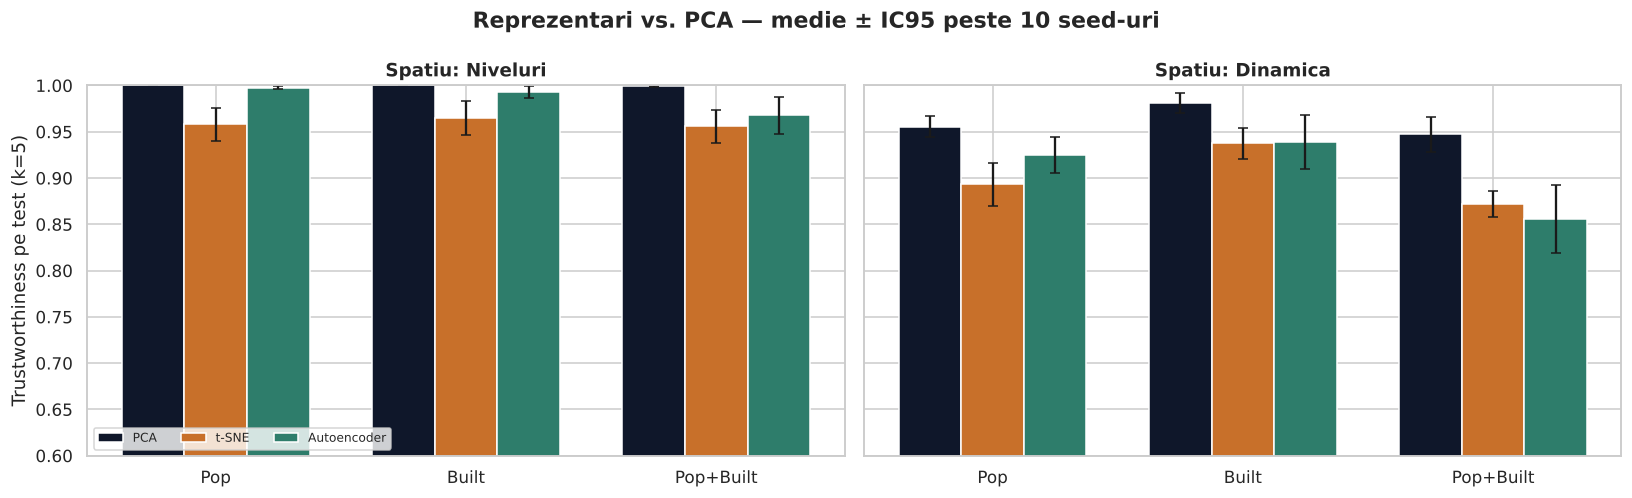

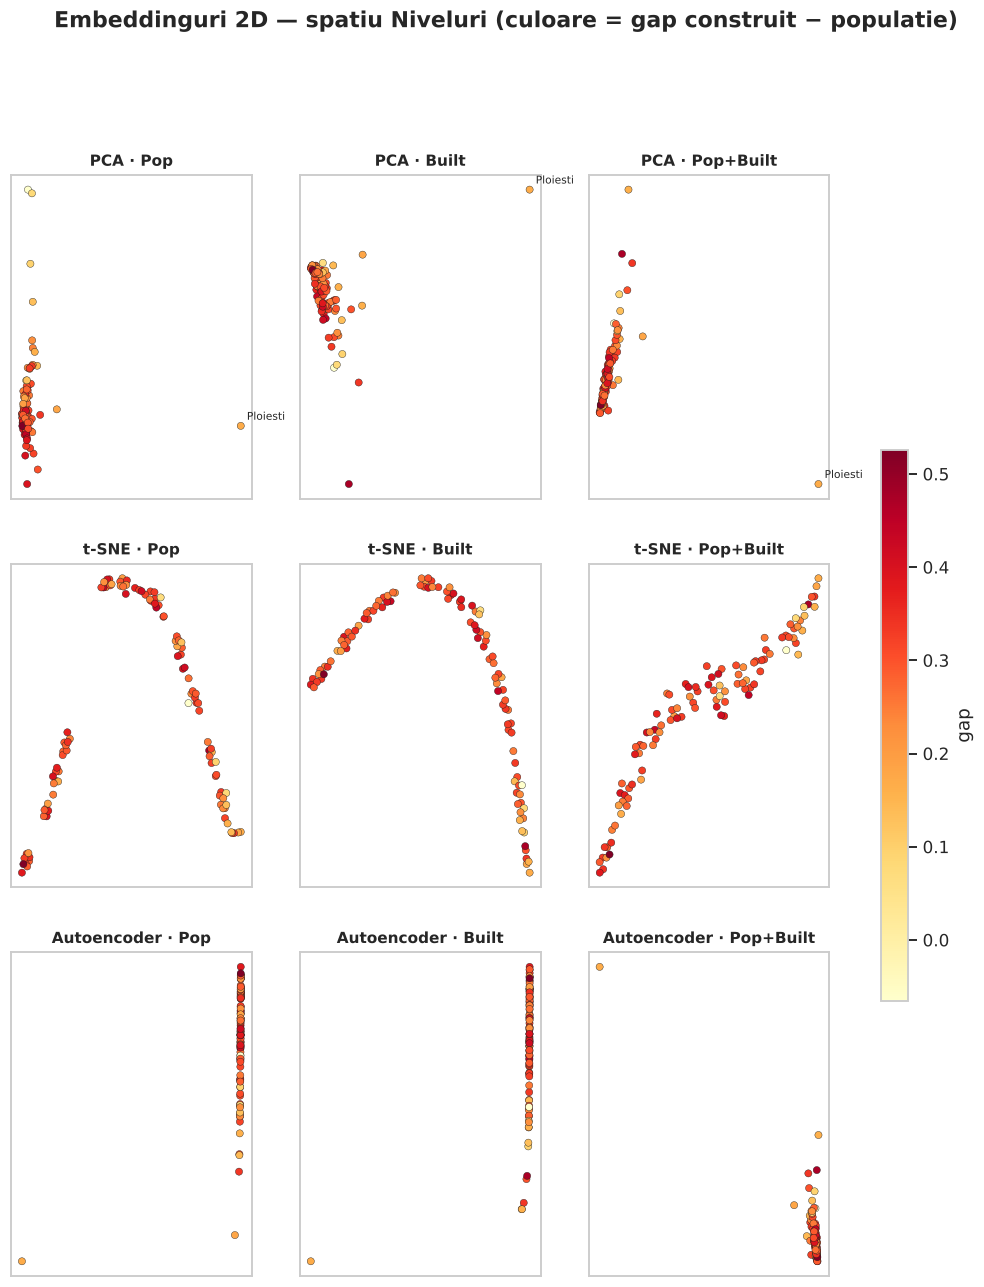

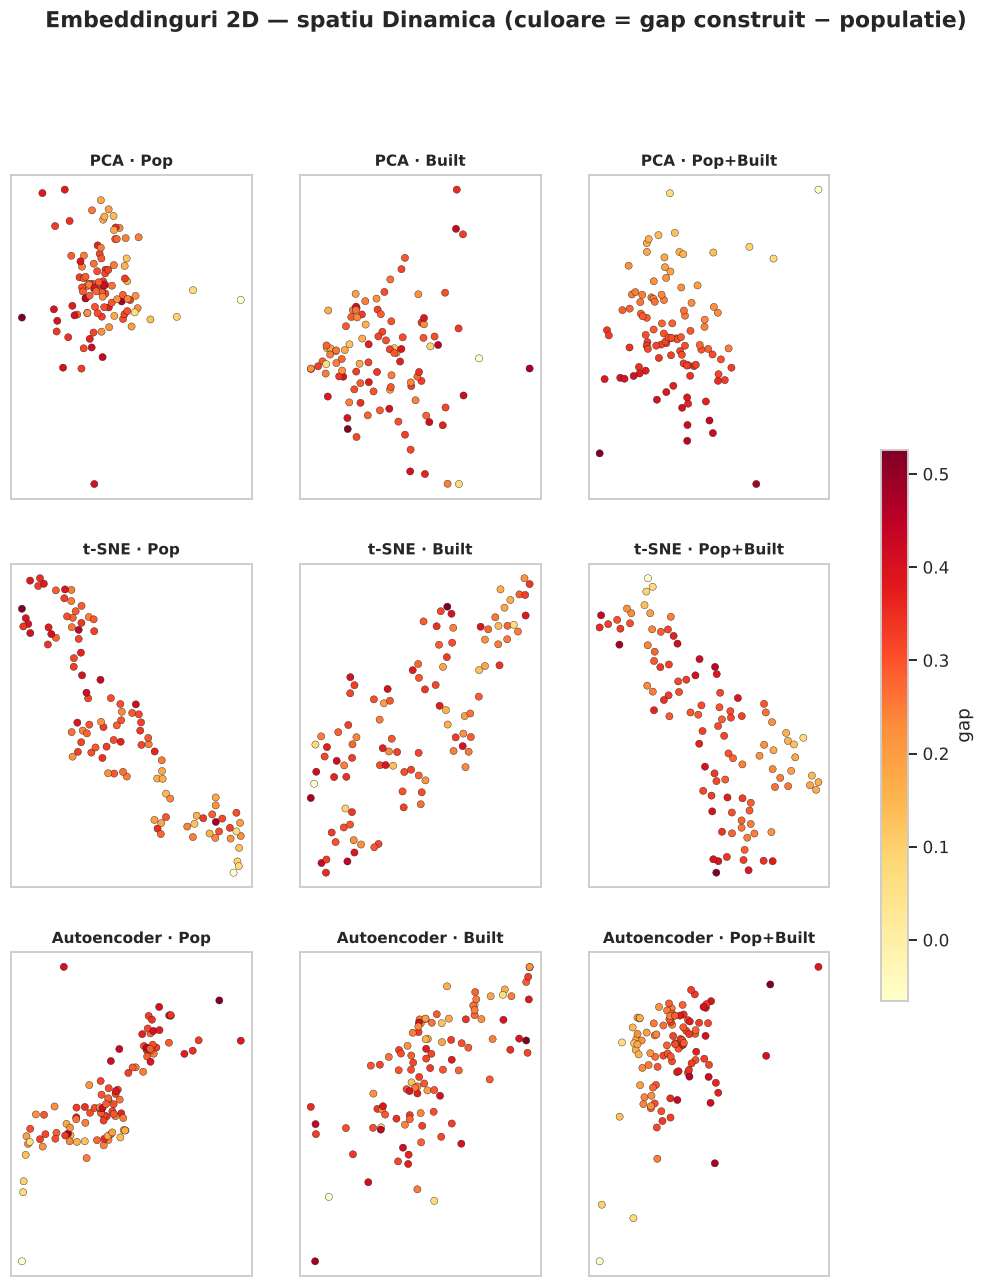

In [11]:
# ---- Figura A: tabelul principal ca bare cu IC95 ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
pal = {"PCA": "#0F172A", "t-SNE": "#C8702A", "Autoencoder": "#2E7D6B"}
for ax, sp in zip(axes, SPACES):
    d = main[main.spatiu == sp]; x = np.arange(3); w = 0.25
    for i, m in enumerate(METHODS):
        dm = d[d.metoda == m].set_index("vedere").loc[["Pop", "Built", "Pop+Built"]]
        ax.bar(x + (i - 1) * w, dm.trust, w, yerr=dm.trust_ci, capsize=3, color=pal[m], label=m)
    ax.set_xticks(x); ax.set_xticklabels(["Pop", "Built", "Pop+Built"]); ax.set_title(f"Spatiu: {sp}"); ax.set_ylim(0.6, 1.0)
axes[0].set_ylabel("Trustworthiness pe test (k=5)"); axes[0].legend(ncol=3, fontsize=8, loc="lower left")
plt.suptitle("Reprezentari vs. PCA — medie ± IC95 peste 10 seed-uri", fontweight="bold"); plt.tight_layout()
plt.show()

# ---- Figura B: embeddinguri 2D, metoda × vedere (spatiul Dinamica si Niveluri) ----
for sp in SPACES:
    fig, axes = plt.subplots(len(METHODS), 3, figsize=(12, 13), squeeze=False)
    for i, m in enumerate(METHODS):
        for j, v in enumerate(["Pop", "Built", "Pop+Built"]):
            Z = emb_cache[(sp, v, m, 0)]
            sc = axes[i, j].scatter(Z[:, 0], Z[:, 1], c=df.gap, cmap="YlOrRd", s=22, edgecolor="k", lw=0.25)
            axes[i, j].set_title(f"{m} · {v}", fontsize=10); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if m == "PCA" and sp == "Niveluri":
                axes[i, j].annotate("Ploiesti", Z[df.UAT_Name.str.contains("Ploiesti").values][0], fontsize=7, xytext=(4, 4), textcoords="offset points")
    plt.suptitle(f"Embeddinguri 2D — spatiu {sp} (culoare = gap construit − populatie)", fontweight="bold", y=0.995)
    fig.colorbar(sc, ax=axes, shrink=0.5, label="gap"); plt.show()

## 7. Sinteza si concluzii CP3

In [12]:
def best_of(sp, view):
    d = main[(main.spatiu == sp) & (main.vedere == view)].set_index("metoda")
    return d.trust.idxmax(), d.trust.max(), d.loc["PCA", "trust"]

print("=== Sinteza automata ===")
for sp in SPACES:
    for v in ["Pop", "Built", "Pop+Built"]:
        b, tb, tp = best_of(sp, v)
        sig = cmp_tab[(cmp_tab.spatiu == sp) & (cmp_tab.vedere == v) & (cmp_tab.metoda == b)]
        extra = "" if b == "PCA" else f" | Δ vs PCA = {sig.delta_trust_vs_PCA.iloc[0]:+.3f} ± {sig.ci95.iloc[0]:.3f} ({'semnificativ' if sig.semnificativ.iloc[0]=='DA' else 'nesemnificativ'})"
        print(f"{sp:9s} {v:10s} → cea mai buna: {b:12s} trust={tb:.3f} (PCA={tp:.3f}){extra}")
print()
n_cmp = len(cmp_tab); n_win = (cmp_tab.castiga == "metoda").sum(); n_pca = (cmp_tab.castiga == "PCA").sum(); n_eq = (cmp_tab.castiga == "egal").sum()
print(f"Comparatii metoda-neliniara vs PCA: {n_cmp} | castigate de metoda: {n_win} | castigate de PCA (semnificativ): {n_pca} | egale: {n_eq}")
print("CCA:", cca_tab[["r1", "null95", "p_perm", "r1_test_medie"]].round(3).to_dict("index"))
print(f"UAT cu populatie ↓ si construit ↑ (2010→2025): {pop_down_built_up.sum()} / {len(df)}")
print("Top 5 UAT dupa gap (construit creste mai mult decat populatia):")
display(df.nlargest(5, "gap")[["UAT_Name", "Pop_2010", "Pop_2025", "Built_2010", "Built_2025", "gap"]].round(3))

=== Sinteza automata ===
Niveluri  Pop        → cea mai buna: PCA          trust=1.000 (PCA=1.000)
Niveluri  Built      → cea mai buna: PCA          trust=1.000 (PCA=1.000)
Niveluri  Pop+Built  → cea mai buna: PCA          trust=0.999 (PCA=0.999)
Dinamica  Pop        → cea mai buna: PCA          trust=0.955 (PCA=0.955)
Dinamica  Built      → cea mai buna: PCA          trust=0.981 (PCA=0.981)
Dinamica  Pop+Built  → cea mai buna: PCA          trust=0.947 (PCA=0.947)

Comparatii metoda-neliniara vs PCA: 12 | castigate de metoda: 0 | castigate de PCA (semnificativ): 12 | egale: 0
CCA: {'Niveluri': {'r1': 0.986, 'null95': 0.549, 'p_perm': 0.002, 'r1_test_medie': 0.883}, 'Dinamica': {'r1': 0.661, 'null95': 0.373, 'p_perm': 0.002, 'r1_test_medie': 0.611}}
UAT cu populatie ↓ si construit ↑ (2010→2025): 96 / 104
Top 5 UAT dupa gap (construit creste mai mult decat populatia):


,UAT_Name,Pop_2010,Pop_2025,Built_2010,Built_2025,gap
94,Tataru,1097,726,0.185,0.207,0.525
18,Aricestii Rahtivani,8342,8033,1.455,2.251,0.474
74,Poienarii Burchii,5254,4430,0.691,0.909,0.445
39,Cocorastii Colt,3189,2829,0.345,0.469,0.429
98,Tomsani,4591,4161,0.564,0.777,0.418


### Concluzii (cifrele provin din rularea de mai sus, 10 seed-uri)
1. **Relatii.** Pop si Built sunt aproape redundante in *niveluri* (Spearman ≈ 0,94; CCA r₁ = 0,99; ambele masoara marimea UAT). In *dinamica* legatura scade la r₁ = 0,66 (CCA, p < 0,01 la permutari; 0,61 pe test), iar acordul vecinilor kNN Pop↔Built este aproape de nivelul aleator (Jaccard 0,05 vs 0,03). **Built aduce informatie noua fata de populatie tocmai in spatiul care raspunde intrebarii.**
2. **Baseline.** PCA nu este depasit: din 12 comparatii (2 metode × 3 vederi × 2 spatii), 0 sunt castigate de metoda neliniara; PCA castiga semnificativ in toate 12. Rezultatul „nu bate baseline-ul” este raportat ca atare.
3. **Reconstructie.** PCA reconstruieste mai bine decat autoencoderul pe test; autoencoderul cu activare `tanh` satureaza pe valorile extreme (Ploiesti) — in seed-urile in care Ploiesti cade in test, R² devine puternic negativ (niveluri/Pop).
4. **Stabilitate.** PCA este determinist (Jaccard 1,00 intre seed-uri). t-SNE: 0,93–0,97 in niveluri, 0,66–0,78 in dinamica. Autoencoder: 0,33–0,73. Pe subperioade, trustworthiness-ul nu se schimba semnificativ in niveluri; in dinamica Pop+Built scade usor de la P1 la P2 (PCA −0,026 ± 0,016; t-SNE si autoencoder nesemnificativ).
5. **Limite.** Doar 4 momente de timp (subperioadele P1/P2 se suprapun partial; pe dinamica, vederile Pop/Built au 2 trasaturi ⇒ PCA k=2 e fara pierderi si comparatia e neinformativa). Fara coordonate nu avem split spatial sau Moran's I. t-SNE foloseste extensie kNN pentru UAT-urile de test. Criteriul binar „construit↑ & populatie↓” nu discrimineaza (96/104), deci folosim indicele `gap`.